# Report for Lab 01 - Pitches 

---
embed-resources: true
echo: false
---

## Introduction

The goal of this lab was to create a model that is able to predict a pitch's type immediately after it is thrown.

Now, accurate and instant pitch labels can improve audience engagement with the mechanics of baseball and allows for groundwork to be laid down for future broadcasting elements. For example, being able to place the correct labels that can be shown both in-stadium and on TV. Things like this can help within not just baseball but sports analytics and entertainment as an industry.    

## Methods

Below are the imports used to make the model. The first four imports are basic imports to handle data wrangling, visualization, and exporting the model. The next three imports are related to model making and scoring, and the last chunk of imports were used for preprocessing the model.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

```
import pandas as pd
from joblib import dump

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
```

### Data

To make our model, we used historical pitching data provided from Statcast, provided by the CS 307 lab website. The pybaseball package was used to interface with Stacast Search which is part of Baseball Savant. After loading the data in, the data was prepared for machine learning. The data was split into training and testing sets. 

In [2]:
pitches_train = pd.read_parquet('https://lab.cs307.org/pitches/data/pitches-train.parquet')
pitches_test = pd.read_parquet('https://lab.cs307.org/pitches/data/pitches-test.parquet')

**First few rows of the training data:**

In [3]:
pitches_train.head(5)

,pitch_type,release_speed,release_spin_rate,pfx_x,pfx_z,stand
0,FF,97.3,2432.0,-0.80,1.61,L
1,FF,97.9,2385.0,-0.93,1.22,L
2,FF,96.6,2390.0,-0.97,1.38,L
3,FS,86.4,1492.0,-1.27,0.50,L
4,FS,88.9,1778.0,-1.14,0.68,R


**First few rows of the testing data:**

In [4]:
pitches_test.head(5)

,pitch_type,release_speed,release_spin_rate,pfx_x,pfx_z,stand
0,FF,96.0,2387,-1.00,1.45,L
1,FS,84.6,1736,-0.63,-0.11,R
2,FS,85.9,1732,-1.31,0.55,R
3,FF,95.4,2304,-1.01,1.22,R
4,FF,96.7,2307,-1.11,1.17,R


**A data dictionary for reference:**

`pitch_type`: 
- (Categorical)  the type of the pitch

`release_speed`: 
- (Numerical) pitch velocity (miles per hour) measured shortly after leaving the pitcher’s hand

`release_spin_rate`: 
- (Numerical)  pitch spin rate (revolutions per minute) measured shortly after leaving the pitcher’s hand

`pfx_x`: 
- (Numerical) horizontal movement (feet) of the pitch from the catcher’s perspective

`pfx_z`: 
- (Numerical) vertical movement (feet) of the pitch from the catcher’s perspective

`stand`: 
- (Categorical) side of the plate batter is standing, either L (left) or R (right)

**General summary statistics concerning the data:**

In [8]:
# summary statistics
X_train = pitches_train.drop('pitch_type', axis = 1)
y_train = pitches_train['pitch_type']
X_test = pitches_test.drop('pitch_type', axis = 1)
y_test = pitches_test['pitch_type']

n_samples = X_train.shape[0]
n_features = X_train.shape[1]
print('Number of samples: ' + str(n_samples) + 
      '\nNumber of features: ' + 
      str(n_features) + 
      '\n_____________')

len_pitch_type = len(pitches_train)
ff_count = len(pitches_train[pitches_train.pitch_type == 'FF'])
fs_count = len(pitches_train[pitches_train.pitch_type == 'FS'])
si_count = len(pitches_train[pitches_train.pitch_type == 'SI'])
sl_count = len(pitches_train[pitches_train.pitch_type == 'SL'])

print('Pitch type counts:\n' + 'ff_count = ' + str(ff_count) +
      '\nfs_count = ' + str(fs_count) + 
      '\nsi_count = ' + str(si_count) + 
      '\nsl_count = ' + str(sl_count) + 
      '\n_____________')

ff_prop = ff_count / len_pitch_type
fs_prop = fs_count / len_pitch_type
si_prop = si_count / len_pitch_type
sl_prop = sl_count / len_pitch_type

print('Pitch type proportions:\n'+'ff_prop = ' + str(ff_prop) +
      '\nfs_prop = ' + str(fs_prop) + 
      '\nsi_prop = ' + str(si_prop) + 
      '\nsl_prop = ' + str(sl_prop) + '\n_____________')

pitches_ff = pitches_train[pitches_train.pitch_type == 'FF']
mv_ff = pitches_ff.release_speed.mean()
std_ff = pitches_ff.release_speed.std()

pitches_fs = pitches_train[pitches_train.pitch_type == 'FS']
mv_fs = pitches_fs.release_speed.mean()
std_fs = pitches_fs.release_speed.std()

pitches_si = pitches_train[pitches_train.pitch_type == 'SI']
mv_si = pitches_si.release_speed.mean()
std_si = pitches_si.release_speed.std()

pitches_sl = pitches_train[pitches_train.pitch_type == 'SL']
mv_sl = pitches_sl.release_speed.mean()
std_sl = pitches_sl.release_speed.std()

print('Velocity by pitch type:\n' + 'MEANS (FF, FS, SI, SL): ' + 
      str(mv_ff) + ', ' + 
      str(mv_fs) + ', ' + 
      str(mv_si) + ', ' + 
      str(mv_sl))

print('STANDARD DEVIATIONS (FF, FS, SI, SL): ' +
      str(std_ff) + ', ' + 
      str(std_fs) + ', ' + 
      str(std_si) + ', ' + 
      str(std_sl) + '\n_____________')

ms_ff = pitches_ff.release_spin_rate.mean()
ms_fs = pitches_fs.release_spin_rate.mean()
ms_si = pitches_si.release_spin_rate.mean()
ms_sl = pitches_sl.release_spin_rate.mean()

rstd_ff = pitches_ff.release_spin_rate.std()
rstd_fs = pitches_fs.release_spin_rate.std()
rstd_si = pitches_si.release_spin_rate.std()
rstd_sl = pitches_sl.release_spin_rate.std()

print('Spin Rate by pitch type:\n' + 'MEANS (FF, FS, SI, SL): ' + 
      str(ms_ff) + ', ' + 
      str(ms_fs) + ', ' + 
      str(ms_si) + ', ' + 
      str(ms_sl))

print('STANDARD DEVIATIONS (FF, FS, SI, SL): ' +
      str(rstd_ff) + ', ' + 
      str(rstd_fs) + ', ' + 
      str(rstd_si) + ', ' + 
      str(rstd_sl))

Number of samples: 2868
Number of features: 5
_____________
Pitch type counts:
ff_count = 1488
fs_count = 959
si_count = 181
sl_count = 240
_____________
Pitch type proportions:
ff_prop = 0.5188284518828452
fs_prop = 0.33437935843793587
si_prop = 0.06311018131101813
sl_prop = 0.08368200836820083
_____________
Velocity by pitch type:
MEANS (FF, FS, SI, SL): 93.95752688172043, 85.96955161626695, 93.31049723756908, 82.74791666666667
STANDARD DEVIATIONS (FF, FS, SI, SL): 1.700910729373256, 1.8217575385959301, 1.739875562677813, 1.8641284078785914
_____________
Spin Rate by pitch type:
MEANS (FF, FS, SI, SL): 2287.09811827957, 1764.0385818561, 2189.022099447514, 2239.4351464435144
STANDARD DEVIATIONS (FF, FS, SI, SL): 101.98396987164645, 177.46977034614454, 113.02649422940647, 96.45268672434175


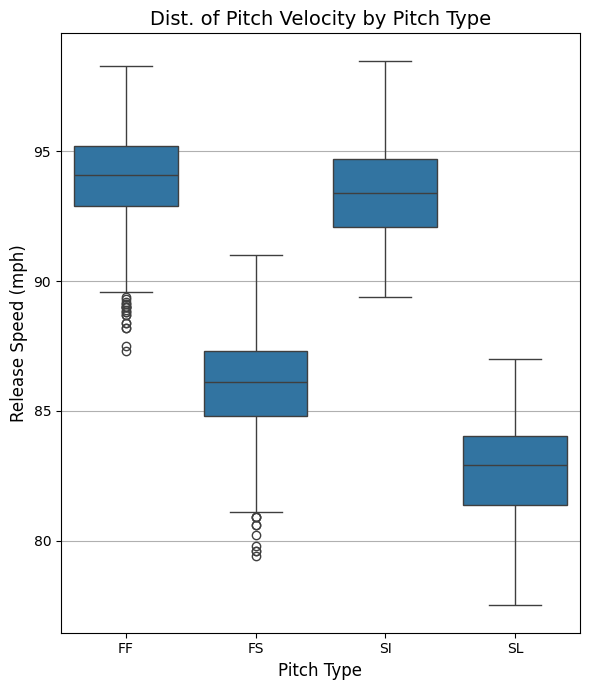

In [9]:
plt.figure(figsize = (6, 7))
sns.boxplot(data = pitches_train, x = "pitch_type", y = "release_speed")
plt.xlabel("Pitch Type", fontsize = 12)
plt.ylabel("Release Speed (mph)", fontsize = 12)
plt.title("Dist. of Pitch Velocity by Pitch Type", fontsize = 14)
plt.grid(axis = "y")
plt.tight_layout()
plt.show()

::: {.quarto-figure-caption}
Figure 1. Boxplot showing the distribution of release speeds across the pitch types.
:::

Fastballs (FF) exhibit the highest median velocity, while sliders (SL) and splitters (FS) are slower, reflecting their offspeed nature.
The narrow spread within each group suggests consistent delivery mechanics, making velocity a key distinguishing feature in pitch-type classification.

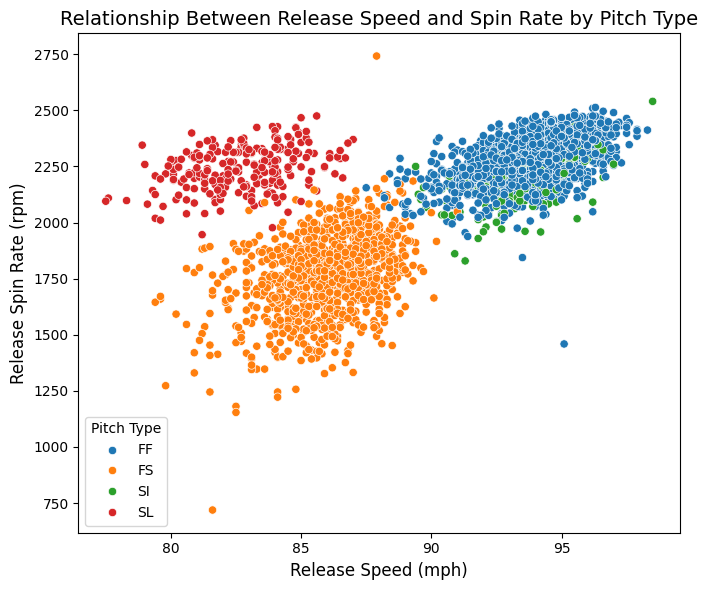

In [10]:
plt.figure(figsize = (7, 6))
sns.scatterplot(data = pitches_train, x = "release_speed", y = "release_spin_rate", hue = "pitch_type")
plt.xlabel("Release Speed (mph)", fontsize = 12)
plt.ylabel("Release Spin Rate (rpm)", fontsize = 12)
plt.title("Relationship Between Release Speed and Spin Rate by Pitch Type", fontsize = 14)
plt.legend(title = "Pitch Type")
plt.tight_layout()
plt.show()

::: {.quarto-figure-caption}
Figure 2. Scatter plot of release speed vs. spin rate, colored by pitch type.
:::

 Faster pitches such as four-seam fastballs (FF) tend to display higher spin rates, while offspeed pitches like splitters (FS) have lower speeds. This visualization helps illustrate between pitch classes.

### Model Development

To prepare for model development, the data was split into 'X' and 'y' train and test sets. Target variable was the pitch type (y), and the feature variables (X) both numeric and categoric, were used.

```{python}
X_train = pitches_train.drop('pitch_type', axis = 1)
y_train = pitches_train['pitch_type']
X_test = pitches_test.drop('pitch_type', axis = 1)
y_test = pitches_test['pitch_type']
```

For model preprocessing, two pipelines were created from the `StandardScaler` and `OneHotEncoder` imports, with the former being used to impute missing values be standardized with the mean and the latter being used to impute missing values with the most frequent category and one-hot encoded. These two pipelines would be combined using the `ColumnTransformer`. The numeric and categorical faetures used were all the ones in the training dataset, using `select_dtypes` to get them, though manual entry would've sufficed as well. This preprocessor was then fit and transformed to the training data.

```{python}
numeric_transformer = make_pipeline(SimpleImputer(strategy = "mean"), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = "most_frequent"), OneHotEncoder())
numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer((numeric_transformer, numeric_features),
                                       (categorical_transformer, categorical_features))
preprocessor.fit(X_train)
preprocessor.transform(X_train)
```

To make the model, a K-nearest Neighbors Classifier was used because it's an easy to use and simple baseline for both numerical and categorical features. The high neighbor count (300) helps with our predictions. `make_pipeline` was used to apply the preprocessor earlier to the model, where the model was then fit to our training set and evaluated onto the test set.

```{python}
model = make_pipeline(preprocessor, KNeighborsClassifier(n_neighbors = 300))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
```

In [11]:
numeric_transformer = make_pipeline(SimpleImputer(strategy = "mean"), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = "most_frequent"), OneHotEncoder())

numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer((numeric_transformer, numeric_features),
                                       (categorical_transformer, categorical_features))
preprocessor.fit(X_train)
preprocessor.transform(X_train)

model = make_pipeline(preprocessor, KNeighborsClassifier(n_neighbors = 300))
model.fit(X_train, y_train)

,steps,"[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline-1', ...), ('pipeline-2', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Results

```{python}
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
```

In [12]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy score of the mode: ' + str(accuracy))

Accuracy score of the mode: 0.9933554817275747


**The model was able to achieve an accuracy score of ~ 0.993**

To visualize our classifier model performance, we are making a confusion matrix:

<Figure size 600x700 with 0 Axes>

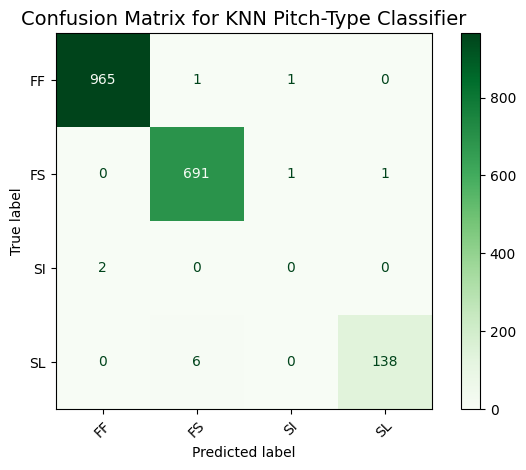

In [13]:
plt.figure(figsize = (6, 7))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap = "Greens", xticks_rotation = 45)
plt.title("Confusion Matrix for KNN Pitch-Type Classifier", fontsize = 14)
plt.tight_layout()
plt.show()

:::{.quarto-figure-caption}
Figure 3. Confusion matrix of actual vs. predicted pitch types.
:::

Strong diagonal elements indicate correct classifications. Off-diagonal cells reveal frequent confusions (e.g., fastballs vs. sinkers), informing potential areas for model improvements or feature refinements/selection. Here, we can see that our model was most confused with 'FF' and 'FS' pitches.

## Discussion

### Would I deploy this model?
I would <b> NOT </b> deploy this model. The model demonstrates that although it is possible to predict pitch types in real time, though this would be valuable for various broadcast overlays, the current model at this point shouldn't be deployed without further measures in place, despite it's high accuracy spore. 

### Risks avoided by not using this model:
- Classification errors/confusion in the model (eg., problems highlighted in Figure 3)
- The scale of real-world data is much greater than the small subset of data used in this model
    - Unclear as to weather or not KNClassifier model could scale to that level
- Not all possible variables are being considered here

### Potential improvements
- Try other classifiers to create our model
- Perform hyperparameter tuning on our model to optimize model performance
- Add/create new features to be used for predicting the target

## Conclusion

Our model serves as a solid concept/potential framework for pitch-type classification. Though it boasts an impressive accuracy score, the design and preprocessing could be further improved for model stability and model scaling. If these potential improvements are made, our approach could potentially be integrated into broadcasting systems.